In [61]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import os

In [62]:
data = pd.read_csv("recursos_humanos (3).csv")
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [63]:
data.head

<bound method NDFrame.head of        satisfaction_level  last_evaluation  number_project  \
0                    0.38             0.53               2   
1                    0.80             0.86               5   
2                    0.11             0.88               7   
3                    0.72             0.87               5   
4                    0.37             0.52               2   
...                   ...              ...             ...   
14994                0.40             0.57               2   
14995                0.37             0.48               2   
14996                0.37             0.53               2   
14997                0.11             0.96               6   
14998                0.37             0.52               2   

       average_montly_hours  time_spend_company  Work_accident  left  \
0                       157                   3              0     1   
1                       262                   6              0     1   
2        

In [64]:
data = pd.get_dummies(data, columns=["sales", "salary"], dtype=int)
data


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [65]:
# Empleados que dejaron y que permanecieron en la empresa
S = data[data.left == 1]
N = data[data.left == 0]


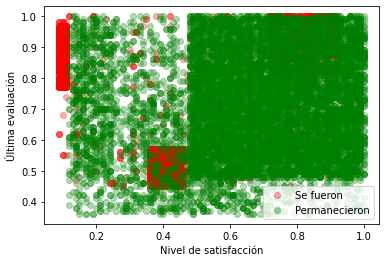

In [66]:
# Diagrama de dispersión
plt.scatter(S.satisfaction_level, S.last_evaluation, color="red", label="Se fueron", alpha=0.3)
plt.scatter(N.satisfaction_level, N.last_evaluation, color="green", label="Permanecieron", alpha=0.3)
plt.xlabel("Nivel de satisfacción")
plt.ylabel("Última evaluación")
plt.legend()
plt.show()


In [67]:
# Separación de variables
y = data.left.values
x_data = data.drop(["left"], axis=1)
y

array([1, 1, 1, ..., 1, 1, 1])

In [68]:
# Normalización de los datos
x = (x_data - np.min(x_data))/(np.max(x_data) - np.min(x_data))
x


/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: In a future version, DataFrame.min(axis=None) will return a scalar min over the entire DataFrame. To retain the old behavior, use 'frame.min(axis=0)' or just 'frame.min()'
  return reduction(axis=axis, out=out, **passkwargs)
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: In a future version, DataFrame.max(axis=None) will return a scalar max over the entire DataFrame. To retain the old behavior, use 'frame.max(axis=0)' or just 'frame.max()'
  return reduction(axis=axis, out=out, **passkwargs)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.318681,0.265625,0.0,0.285047,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.780220,0.781250,0.6,0.775701,0.500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.021978,0.812500,1.0,0.822430,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.692308,0.796875,0.6,0.593458,0.375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.307692,0.250000,0.0,0.294393,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.340659,0.328125,0.0,0.257009,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14995,0.307692,0.187500,0.0,0.299065,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14996,0.307692,0.265625,0.0,0.219626,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14997,0.021978,0.937500,0.8,0.859813,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [69]:
# Bases de entrenamiento y prueba
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=1)


In [70]:
# Modelo KNN (K vecinos más cercanos)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train, y_train)
prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test, y_test))


Score:  0.9453333333333334


In [71]:
# Comparación de los valores de K
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    prediction = knn.predict(x_test)
    print("K =", k, "Score: ", knn.score(x_test, y_test))


K = 1 Score:  0.9617777777777777
K = 2 Score:  0.9577777777777777
K = 3 Score:  0.9453333333333334
K = 4 Score:  0.946
K = 5 Score:  0.9393333333333334
K = 6 Score:  0.9446666666666667
K = 7 Score:  0.9411111111111111
K = 8 Score:  0.9393333333333334
K = 9 Score:  0.9324444444444444
K = 10 Score:  0.934
K = 11 Score:  0.9293333333333333
K = 12 Score:  0.9311111111111111
K = 13 Score:  0.9262222222222222
K = 14 Score:  0.9288888888888889
K = 15 Score:  0.9253333333333333
K = 16 Score:  0.9264444444444444
K = 17 Score:  0.9228888888888889
K = 18 Score:  0.9211111111111111
K = 19 Score:  0.9186666666666666
K = 20 Score:  0.9188888888888889


In [72]:

# Modelo KNN con K = 1
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

print("Score: ", knn.score(x_test, y_test))


Score:  0.9617777777777777


In [77]:
# Modelo KNN con K = 1
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

In [76]:
# Creación de la matriz de confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, prediction)
cm

array([[3296,  120],
       [  52, 1032]])

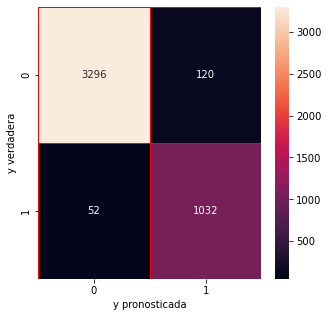

In [78]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y verdadera")
plt.show()


In [79]:
# Cálculo de las precisiones
correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[1,0] + cm[0,1]

PrecisionGlobal = correctos / (correctos + Incorrectos)
PrecisionNo = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionSi = cm[1,1] / (cm[1,1] + cm[0,1])

print("Precisión global:", PrecisionGlobal)
print("Precisión de empleados que permanecen:", PrecisionNo)
print("Precisión de empleados que se van:", PrecisionSi)


Precisión global: 0.9617777777777777
Precisión de empleados que permanecen: 0.984468339307049
Precisión de empleados que se van: 0.8958333333333334


In [80]:
# Tabla comparativa de precisiones
resultados = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    prediction = knn.predict(x_test)

    cm = confusion_matrix(y_test, prediction)

    correctos = cm[0,0] + cm[1,1]
    Incorrectos = cm[1,0] + cm[0,1]

    PrecisionGlobal = correctos / (correctos + Incorrectos)
    PrecisionNo = cm[0,0] / (cm[0,0] + cm[1,0])
    PrecisionSi = cm[1,1] / (cm[1,1] + cm[0,1])

    resultados.append([k, PrecisionGlobal, PrecisionNo, PrecisionSi])

tabla = pd.DataFrame(resultados, columns=["K", "Precisión global", "Precisión No", "Precisión Sí"])
tabla


,K,Precisión global,Precisión No,Precisión Sí
0,1,0.961778,0.984468,0.895833
1,2,0.957778,0.968895,0.921698
2,3,0.945333,0.975120,0.859966
3,4,0.946000,0.960790,0.897824
4,5,0.939333,0.962070,0.868972
5,6,0.944667,0.959652,0.895735
6,7,0.941111,0.960269,0.880223
7,8,0.939333,0.955375,0.886559
8,9,0.932444,0.956038,0.858456
9,10,0.934000,0.953475,0.870877


In [85]:
# Comparación de sensibilidad para K = 1 y K = 2
for k in range(1, 3):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    prediction = knn.predict(x_test)

    cm = confusion_matrix(y_test, prediction)

    sensibilidad = cm[1,1] / (cm[1,1] + cm[1,0])

    print("K =", k, "Sensibilidad:", sensibilidad)



K = 1 Sensibilidad: 0.9520295202952029
K = 2 Sensibilidad: 0.9012915129151291


In [88]:
# Modelo KNN con K = 1
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)

prediction = knn.predict(x_test)


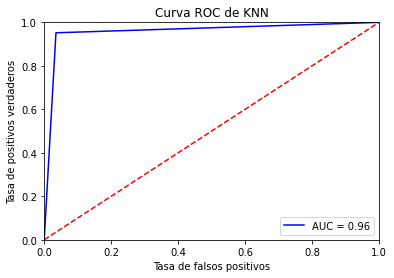

In [89]:

from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_scores = knn.predict_proba(x_test)

fpr, tpr, threshold = roc_curve(y_test, y_scores[:,1])
roc_auc = auc(fpr, tpr)

plt.title("Receiver Operating Characteristic")
plt.plot(fpr, tpr, 'b', label='AUC = %0.2f' % roc_auc)
plt.legend(loc="lower right")
plt.plot([0,1],[0,1], 'r--')
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")
plt.title("Curva ROC de KNN")
plt.show()
